# Эксперимент: расширение словесных n-грамм TF-IDF `(1,3) → (1,6)`

Воспроизводимый разбор результатов эксперимента без необходимости в `.joblib`: метрики, коллизии TF-IDF, переобучение на шаблонах и примеры исправлений/ошибок.

In [1]:
from pathlib import Path
import json
from IPython.display import display, Markdown, Image
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'avito_compare').is_dir() and (p / 'output').is_dir())
OUT = ROOT / 'output/ngram-expansion-experiment'
data = json.loads((OUT / 'analysis.json').read_text(encoding='utf-8'))
configs = data['configs']
def show_table(headers, rows):
    md_txt = '| ' + ' | '.join(headers) + ' |\n| ' + ' | '.join(['---']*len(headers)) + ' |\n'
    md_txt += '\n'.join('| ' + ' | '.join(map(str, r)) + ' |' for r in rows)
    display(Markdown(md_txt))
rows = []
for c in configs:
    m = data['measurements'][c]
    vc = data['v2_collisions'][c]
    se = data['slice_evaluations'][c]
    rows.append([
        c, m['dimensions']['word'], m['dimensions']['total'],
        f"{vc['conflicting_src_vec_groups']} ({vc['vector_collision_groups_any']})",
        f"{se['public_validation']['micro_f1']:.5f}",
        f"{se['v2_test']['micro_f1']:.5f}",
        f"{se['v2_problem_lists']['both_status_lists_1152']['micro_f1']:.5f}",
        f"{se['train_diagnostic']['v2_train']['micro_f1']:.5f}",
        f"{m['fit_wall_seconds']:.1f}s", f"{m['fit_peak_process_rss_mib']:.0f} MiB"
    ])
show_table(['Конфиг', 'Word dims', 'Total dims', 'Коллизии mcId+vec (vec)', 'Public F1', 'v2_test F1', 'Списки 1152 F1', 'v2_train F1', 'Fit', 'RSS'], rows)

| Конфиг | Word dims | Total dims | Коллизии mcId+vec (vec) | Public F1 | v2_test F1 | Списки 1152 F1 | v2_train F1 | Fit | RSS |
| --- | --- | --- | --- | --- | --- | --- | --- | --- | --- |
| ref_46k | 18000 | 46000 | 231 (177) | 0.93002 | 0.44701 | 0.00000 | 0.97643 | 33.0s | 559 MiB |
| A_1_3_uncapped | 117167 | 145167 | 0 (48) | 0.92759 | 0.44617 | 0.00000 | 0.97704 | 29.8s | 566 MiB |
| B_1_4_uncapped | 181100 | 209100 | 0 (48) | 0.92851 | 0.44241 | 0.00000 | 0.98725 | 29.1s | 623 MiB |
| C_1_5_uncapped | 246348 | 274348 | 0 (48) | 0.92771 | 0.44152 | 0.00000 | 0.98875 | 21.7s | 747 MiB |
| D_1_6_uncapped | 311533 | 339533 | 0 (48) | 0.92716 | 0.44322 | 0.00000 | 0.98913 | 28.5s | 766 MiB |

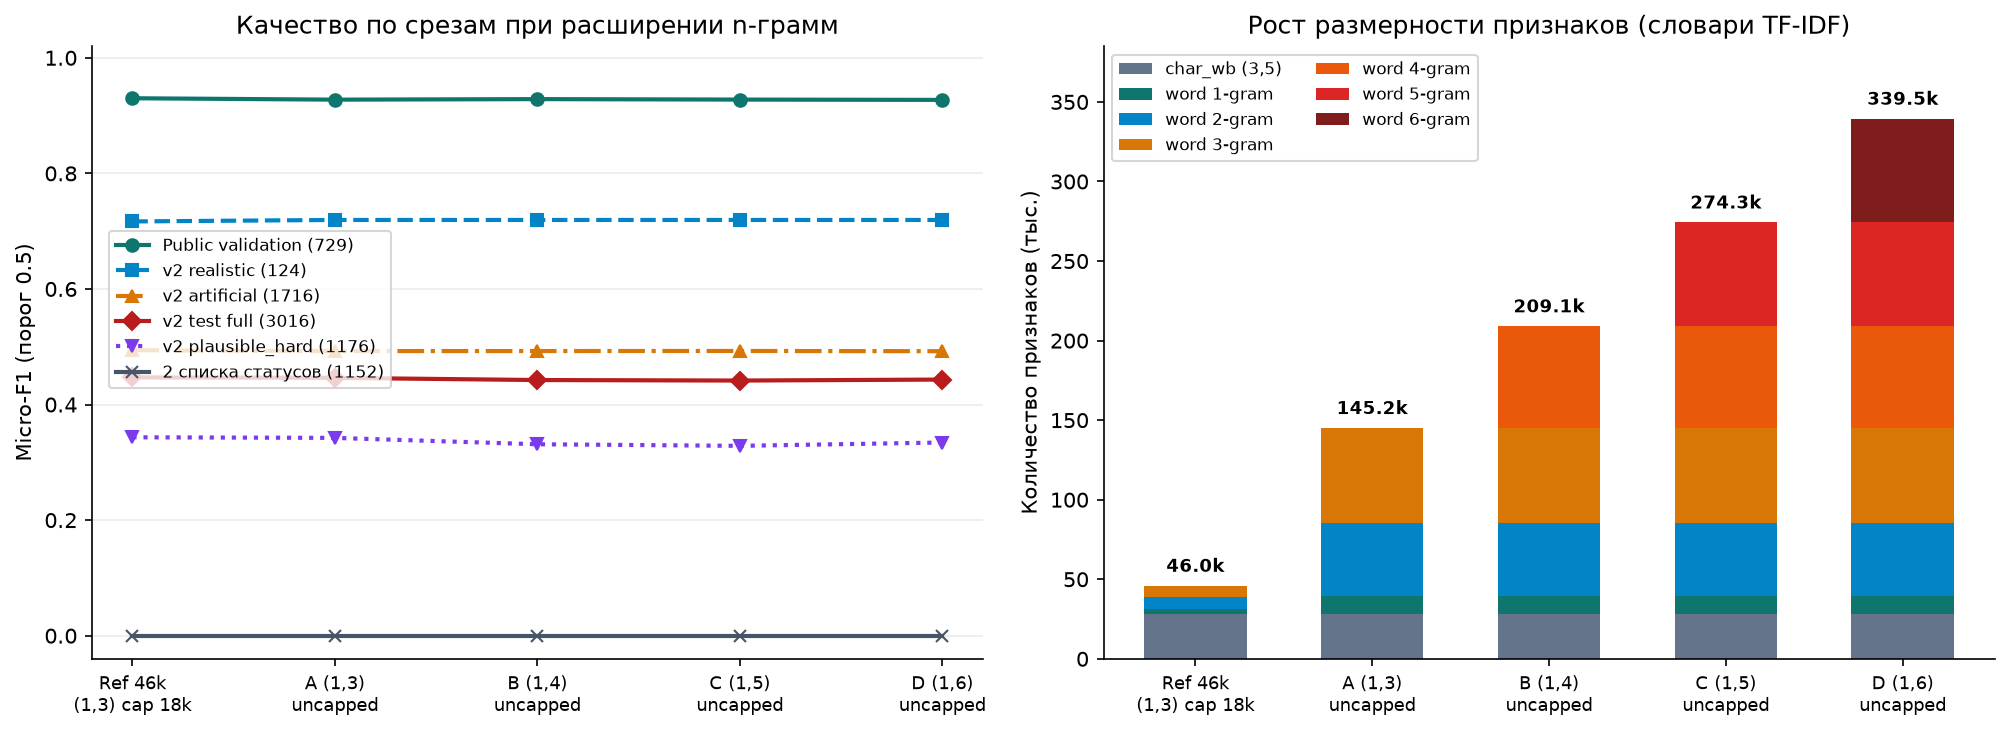

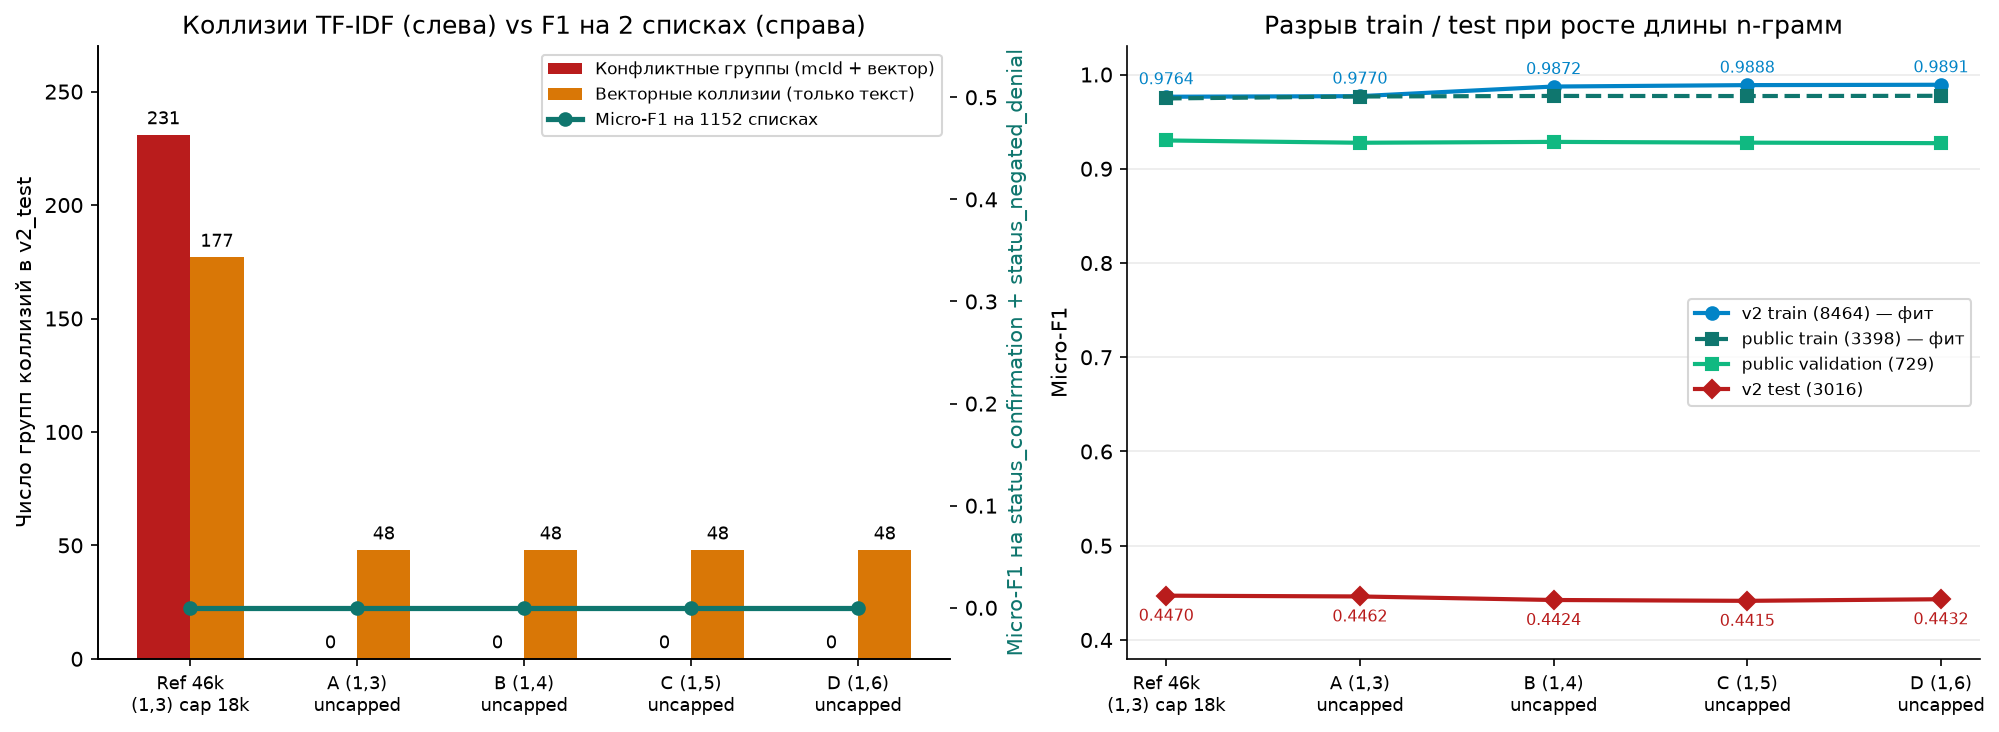

In [2]:
display(Image(filename=str(OUT / '01_metrics_and_dimensions.png')))
display(Image(filename=str(OUT / '02_collisions_and_overfitting.png')))

In [3]:
print('Корреляция числа конфликтных групп и v2_test Micro-F1:', data['correlation_collisions_vs_v2_f1'])
print('Доля L2^2 веса модели по длинам n-грамм:')
for c in configs:
    print(c, {k: round(v, 4) for k, v in data['weight_analysis'][c]['l2_sq_share'].items()})

Корреляция числа конфликтных групп и v2_test Micro-F1: {'conflicting_groups': [231, 0, 0, 0, 0], 'v2_micro_f1': [0.44700530705079605, 0.44617024516522, 0.44240757714634893, 0.4415227029506192, 0.4432234432234432], 'status_lists_1152_f1': [0.0, 0.0, 0.0, 0.0, 0.0], 'collision_642_f1': [0.0, 0.0, 0.0, 0.0, 0.0], 'pearson_r_groups_vs_v2_f1': 0.68532283807431}
Доля L2^2 веса модели по длинам n-грамм:
ref_46k {'char_wb': 0.4126, 'word_1': 0.0906, 'word_2': 0.1966, 'word_3': 0.3002}
A_1_3_uncapped {'char_wb': 0.4283, 'word_1': 0.0647, 'word_2': 0.1908, 'word_3': 0.3162}
B_1_4_uncapped {'char_wb': 0.4284, 'word_1': 0.0485, 'word_2': 0.1207, 'word_3': 0.1806, 'word_4': 0.2217}
C_1_5_uncapped {'char_wb': 0.4353, 'word_1': 0.0405, 'word_2': 0.0911, 'word_3': 0.1268, 'word_4': 0.1487, 'word_5': 0.1576}
D_1_6_uncapped {'char_wb': 0.4433, 'word_1': 0.0359, 'word_2': 0.0755, 'word_3': 0.0999, 'word_4': 0.1132, 'word_5': 0.1168, 'word_6': 0.1155}
